# 07_04 Thompson Sampling and Multi-Armed Bandits

**Learning objectives**
- Formulate the **exploration-exploitation trade-off** as a **multi-armed bandit** and measure performance by **regret**.
- Implement **uniform allocation (A/B/n)**, **$\varepsilon$-greedy**, **UCB1** and **Thompson sampling**, and compare their regret.
- Explain why Thompson sampling is **probability matching**: each arm is played with the posterior probability of being the best.
- Use the **Lai-Robbins** bound as a benchmark, and see when a bandit beats a fixed A/B test (and when updates are delayed).

**Prerequisites:** [07_01 Bayesian updating](07_01_bayesian_updating_conjugates.ipynb), [07_02 Credible intervals](07_02_credible_intervals_predictive.ipynb) ($P(\text{best})$), [06_07 A/B testing](../../module_06_inference/notebooks/06_07_ab_testing.ipynb), [01_01 Bernoulli and Binomial](../../module_01_discrete/notebooks/01_01_bernoulli_binomial.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap
With a Beta$(a,b)$ prior and $s$ successes and $f$ failures an arm's click rate has posterior Beta$(a+s,\,b+f)$ (07_01), and the probability that an arm is the best of several is estimated by sampling from the posteriors (07_02). A fixed A/B/n test splits traffic equally for a pre-set sample size, then decides (06_07).

## 3. Intuition and story
You run an online shop with three banner designs and about 10,000 visitors this week. An equal split gives each banner a third of the visitors, including the bad ones, until the test ends. A **bandit** adapts while it learns: each visitor is shown the banner that currently looks best, but with enough curiosity about the others to avoid being fooled by early luck. The cost of not knowing the best banner is the **regret**: the clicks we would have gained by always showing the best one.

**Thompson sampling** has a one-line rule that is both Bayesian and practical: *draw one plausible click rate for each banner from its posterior and show the banner with the highest draw.* Uncertain banners are sometimes optimistic draws, so they get explored; banners that are clearly worse are drawn above the leader only rarely, so they quickly fade away.

## 4. Formal definitions

$K$ arms with unknown success probabilities $p_1,\dots,p_K$, best arm $p^*=\max_kp_k$. At each step $t=1,\dots,T$ we choose an arm $A_t$ and observe a reward $R_t\sim\mathrm{Bernoulli}(p_{A_t})$.

**Cumulative (pseudo-)regret:** $\ \mathrm{Regret}(T)=\sum_{t=1}^T\big(p^*-p_{A_t}\big)=\sum_k\Delta_k\,N_k(T)$, with gaps $\Delta_k=p^*-p_k$ and pull counts $N_k(T)$.

| Policy | Rule at step $t$ |
|---|---|
| **Uniform (A/B/n)** | cycle through the arms equally |
| **$\varepsilon$-greedy** | with probability $\varepsilon$ a random arm, otherwise the arm with the highest observed rate |
| **UCB1** | the arm maximising $\hat p_k+\sqrt{2\ln t/N_k}$ (optimism in the face of uncertainty) |
| **Thompson sampling** | draw $\tilde p_k\sim\mathrm{Beta}(1+s_k,1+f_k)$ for each arm and play $\arg\max_k\tilde p_k$ |

**Lai-Robbins lower bound:** for any reasonable policy, $\ \liminf_{T\to\infty}\dfrac{E[\mathrm{Regret}(T)]}{\ln T}\ \ge\ \sum_{k:\,p_k<p^*}\dfrac{\Delta_k}{\mathrm{KL}(p_k\,\|\,p^*)}$, with $\mathrm{KL}(p\|q)=p\ln\frac pq+(1-p)\ln\frac{1-p}{1-q}$.

## 5. Derivations

### 5.1 Thompson sampling is probability matching
If $\tilde p_k$ are drawn independently from the posteriors, the probability of playing arm $k$ is $P(\tilde p_k=\max_j\tilde p_j)=P(\theta_k=\max_j\theta_j\mid\text{data})$, i.e. exactly the posterior probability that arm $k$ is the best (07_02). **In plain words.** Each banner is shown as often as we believe it to be the winner: strong favourites are shown most of the time, plausible contenders get a share, and hopeless ones almost none.

### 5.2 Regret grows only logarithmically
A suboptimal arm needs about $\ln T/\mathrm{KL}(p_k\|p^*)$ pulls before the data separate it from the best arm (the data must beat the log-likelihood ratio threshold $\ln T$), and each pull costs $\Delta_k$. Summing gives the Lai-Robbins constant. Thompson sampling with Beta priors attains this bound asymptotically for Bernoulli arms (Kaufmann et al., Agrawal and Goyal). **In plain words.** Doubling the horizon adds only a fixed amount of regret; a fixed split loses $\bar\Delta\,T$ and grows linearly.

### 5.3 Why a fixed split loses linearly
Uniform allocation plays every arm $T/K$ times: regret $=\frac TK\sum_k\Delta_k$, linear in $T$.

### 5.4 $\varepsilon$-greedy
Exploring with a fixed $\varepsilon$ wastes a share $\varepsilon\bar\Delta$ of the steps forever (linear regret); with $\varepsilon_t\propto1/t$ it can reach logarithmic regret but needs the gaps to be tuned.

### 5.5 Delayed feedback
If posteriors are updated only every $B$ steps (daily batches), the policy acts on stale information for up to $B$ steps; the extra regret is of order $B\,\Delta$ per arm change and is small compared with the benefit when $B\ll T$.

## 6. Properties and relationships
- **A bandit is not a hypothesis test:** it minimises regret, not the error probability of declaring a winner; with near-equal arms it keeps exploring both, losing almost nothing (Example 2).
- **Inference after a bandit is biased** (adaptive sampling): the naive estimates of the arms played less often are biased; use the posterior with the full data, or reserve a small exploration share.
- **Contextual bandits** add features of the user (linear Thompson sampling, LinUCB); **non-stationary bandits** use discounting; **Gaussian Thompson sampling** handles revenue.
- **Link to ML and AI:** recommender systems, ad placement, hyper-parameter search, A/B/n testing at scale, LLM prompt selection and routing, and **reinforcement learning** (the bandit is the one-state MDP; exploration in RL follows the same ideas).

## 7. The simulators

All four policies are written once, vectorised over many independent runs. `play` returns the mean cumulative regret curve, the final regret of every run, and the average share of impressions given to each arm.

In [2]:
def play(policy, p, T, R, seed, eps=0.1, batch=1):
    g = np.random.default_rng(seed); p = np.asarray(p, float); K = p.size; s = np.zeros((R, K)); f = np.zeros((R, K)); s_seen, f_seen = s.copy(), f.copy(); pbest = p.max(); reg = np.zeros(T); fin = np.zeros(R); cnt = np.zeros((R, K)); idx = np.arange(R)
    for t in range(T):
        n = s_seen + f_seen
        if policy == "uniform": a = np.full(R, t % K)
        elif policy == "eps":
            greedy = np.argmax(np.where(n == 0, 1.0, s_seen / np.maximum(n, 1)) + 1e-9 * g.random((R, K)), axis=1); a = np.where(g.random(R) < eps, g.integers(0, K, R), greedy)
            if t < K: a = np.full(R, t)
        elif policy == "ucb":
            a = np.argmax(np.where(n == 0, np.inf, s_seen / np.maximum(n, 1) + np.sqrt(2 * np.log(t + 1) / np.maximum(n, 1))), axis=1)
        else: a = np.argmax(g.beta(1 + s_seen, 1 + f_seen), axis=1)
        win = g.random(R) < p[a]; s[idx, a] += win; f[idx, a] += ~win; cnt[idx, a] += 1; r = pbest - p[a]; reg[t] = r.mean(); fin += r
        if (t + 1) % batch == 0: s_seen, f_seen = s.copy(), f.copy()
    return np.cumsum(reg), fin, cnt.mean(axis=0) / T
# sanity check: with one arm much better, Thompson must put nearly all pulls on it
c_, fin_, sh_ = play("ts", [0.05, 0.5], 500, 100, 0); print("share of pulls on the better arm:", round(sh_[1], 3)); assert sh_[1] > 0.9

share of pulls on the better arm: 0.98


## 8. 2D visuals

### 8.1 One Thompson run: the posteriors learn which arm is best
Three banners with true click rates 4 %, 6 % and 10 %; posteriors after 0, 100, 1,000 and 10,000 impressions of a single run, with the number of times each arm was shown.

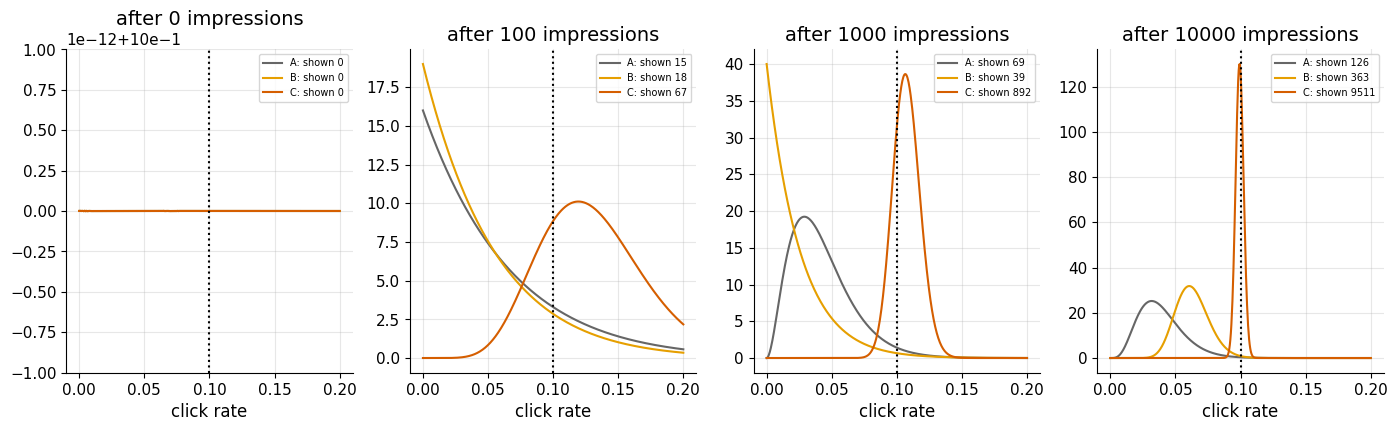

impressions per banner after 10,000: [ 126.  363. 9511.] | regret of this run: 22.1 clicks


In [3]:
ptrue = np.array([0.04, 0.06, 0.10]); g = np.random.default_rng(3); s_ = np.zeros(3); f_ = np.zeros(3); snaps = {}; pull = np.zeros(3); xg = np.linspace(0, 0.2, 500)
for t in range(1, 10001):
    a = int(np.argmax(g.beta(1 + s_, 1 + f_))); win = g.random() < ptrue[a]; s_[a] += win; f_[a] += 1 - win; pull[a] += 1
    if t in (100, 1000, 10000): snaps[t] = (s_.copy(), f_.copy(), pull.copy())
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), sharey=False)
for ax, (t, (ss, ff, pl)) in zip(axes, [(0, (np.zeros(3), np.zeros(3), np.zeros(3)))] + list(snaps.items())):
    for k, colr in enumerate([NEUTRAL, SIM, HIGHLIGHT]): ax.plot(xg, stats.beta.pdf(xg, 1 + ss[k], 1 + ff[k]), color=colr, label=f"{'ABC'[k]}: shown {int(pl[k])}")
    ax.axvline(0.10, color="black", linestyle=":"); ax.set_title(f"after {t} impressions"); ax.set_xlabel("click rate"); ax.legend(fontsize=7)
plt.show()
print("impressions per banner after 10,000:", pull, "| regret of this run:", round(((ptrue.max() - ptrue) * pull).sum(), 1), "clicks")
assert pull[2] > 8000 and pull.sum() == 10000

### 8.2 Cumulative regret of the four policies
Mean over 300 runs of 10,000 impressions: uniform grows linearly; $\varepsilon$-greedy also grows linearly but with a much smaller slope (its exploration costs about $\varepsilon\bar\Delta$ per step); Thompson sampling bends into a logarithmic curve; UCB1 is logarithmic too but its generous exploration bonus makes it pay more at this horizon.

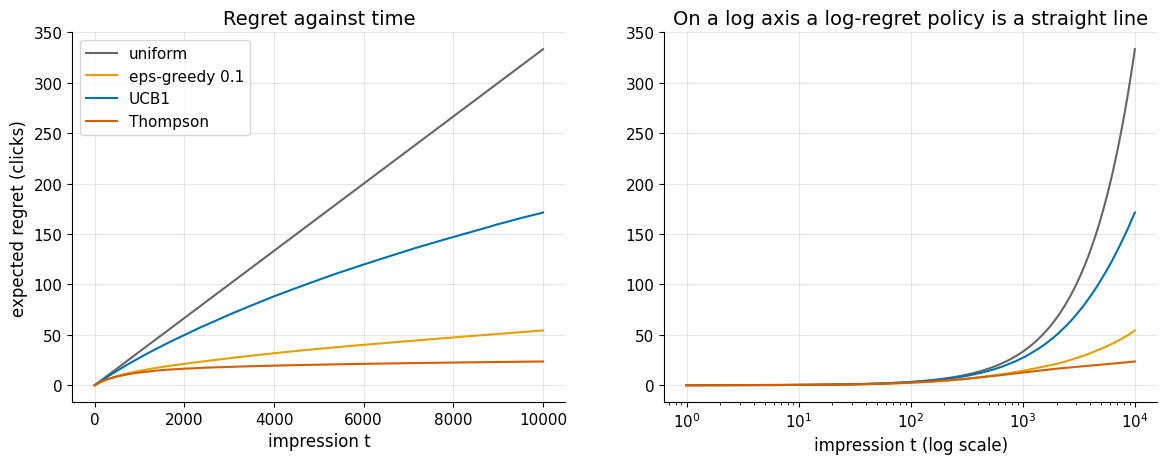

{'uniform': (np.float64(333.4), np.float64(0.0), array([0.333, 0.333, 0.333])), 'eps-greedy 0.1': (np.float64(54.4), np.float64(45.9), array([0.039, 0.077, 0.884])), 'UCB1': (np.float64(171.4), np.float64(14.5), array([0.143, 0.213, 0.643])), 'Thompson': (np.float64(23.6), np.float64(11.1), array([0.017, 0.033, 0.95 ]))}


In [4]:
R, Tn = 300, 10000; res = {nm: play(pol, ptrue, Tn, R, i, eps=0.1) for i, (nm, pol) in enumerate([("uniform", "uniform"), ("eps-greedy 0.1", "eps"), ("UCB1", "ucb"), ("Thompson", "ts")])}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8)); tt = np.arange(1, Tn + 1)
for (nm, (c, fin, sh)), colr in zip(res.items(), [NEUTRAL, SIM, MAIN, HIGHLIGHT]): axes[0].plot(tt, c, color=colr, label=nm); axes[1].plot(tt, c, color=colr, label=nm)
axes[1].set_xscale("log"); axes[0].set_xlabel("impression t"); axes[0].set_ylabel("expected regret (clicks)"); axes[0].legend(); axes[0].set_title("Regret against time"); axes[1].set_xlabel("impression t (log scale)"); axes[1].set_title("On a log axis a log-regret policy is a straight line")
plt.show()
print({nm: (round(c[-1], 1), round(fin.std(), 1), np.round(sh, 3)) for nm, (c, fin, sh) in res.items()})
assert res["uniform"][0][-1] > 300 and res["Thompson"][0][-1] < 0.5 * res["eps-greedy 0.1"][0][-1] and res["Thompson"][0][-1] < res["UCB1"][0][-1]

### 8.3 Where the impressions go
Share of the 10,000 impressions given to each banner by each policy.

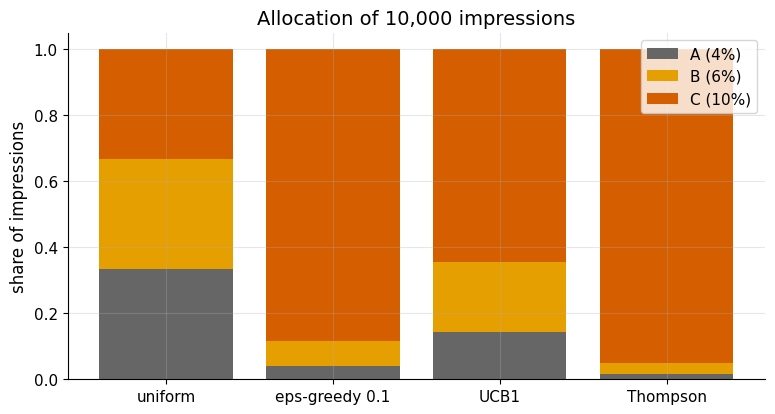

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5)); bot = np.zeros(len(res))
for k, (colr, nm) in enumerate(zip([NEUTRAL, SIM, HIGHLIGHT], ["A (4%)", "B (6%)", "C (10%)"])): vals = np.array([res[p][2][k] for p in res]); ax.bar(list(res), vals, bottom=bot, color=colr, label=nm); bot += vals
ax.set_ylabel("share of impressions"); ax.legend(); ax.set_title("Allocation of 10,000 impressions")
plt.show()

## 9. 3D visuals

### 9.1 Static: Thompson regret over (gap, horizon)
Two arms with success rates 0.10 and $0.10-\Delta$. The surface is the average cumulative regret of Thompson sampling: it grows like $\ln T$ along the horizon axis and, for a fixed horizon, is largest for *intermediate* gaps (a tiny gap costs little per step, a huge gap is found quickly).

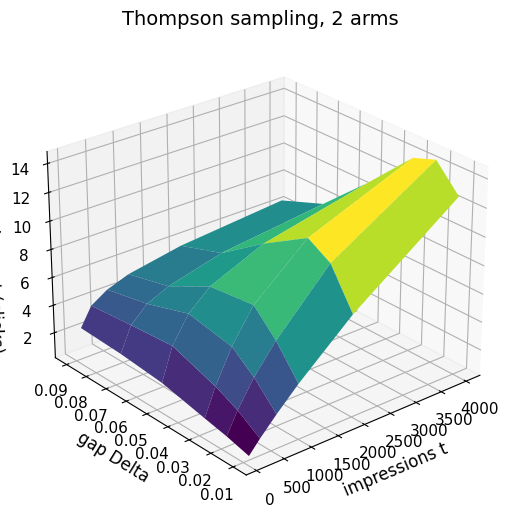

[12.7 14.5 13.9 10.7  7.7  6.5]


In [6]:
gaps = np.array([0.01, 0.02, 0.03, 0.05, 0.07, 0.09]); Tc = 4000; ck = np.array([100, 300, 600, 1000, 2000, 4000]); REG = np.array([play("ts", [0.10, 0.10 - d], Tc, 150, int(d * 1000))[0][ck - 1] for d in gaps])
Cg, Gg = np.meshgrid(ck, gaps); fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(Cg, Gg, REG, cmap="viridis", edgecolor="none"); ax.set_xlabel("impressions t"); ax.set_ylabel("gap Delta"); ax.set_zlabel("expected regret (clicks)"); ax.set_title("Thompson sampling, 2 arms"); ax.view_init(elev=26, azim=-130)
plt.show(); print(np.round(REG[:, -1], 1))
assert REG[:, -1].argmax() in (1, 2, 3) and (REG[:, 1:] >= REG[:, :-1] - 0.5).all()

### 9.2 Interactive Plotly version of 9.1

In [7]:
fig = go.Figure(go.Surface(x=ck, y=gaps, z=REG, colorscale="Viridis")); fig.update_layout(title="Thompson regret", width=760, height=560, scene=dict(xaxis_title="impressions", yaxis_title="gap", zaxis_title="regret")); fig.show()

### 9.3 Static: Thompson sampling's share of the best arm over (time, number of arms)
The share of impressions going to the best arm in a window of 200 impressions, for $K=2$ to 8 arms with rates 0.05 to 0.10 spread evenly: more arms need more time to find the best.

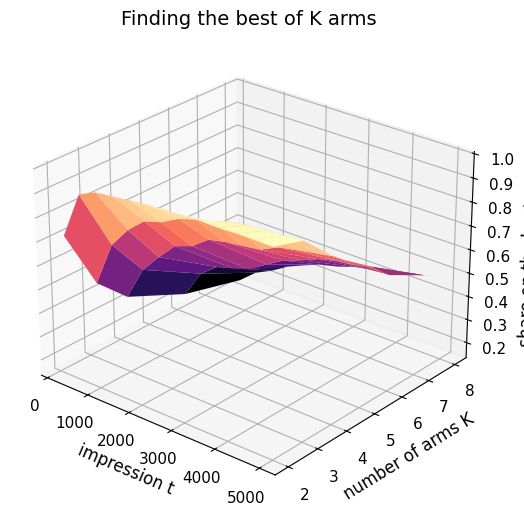

In [8]:
Ks = np.array([2, 3, 4, 6, 8]); wins = np.arange(200, 5001, 400); SH = np.zeros((Ks.size, wins.size))
for i, K in enumerate(Ks):
    pk = np.linspace(0.05, 0.10, K); g = np.random.default_rng(i); sK = np.zeros((100, K)); fK = np.zeros((100, K)); hit = np.zeros(5000); idx = np.arange(100)
    for t in range(5000):
        a = np.argmax(g.beta(1 + sK, 1 + fK), axis=1); w = g.random(100) < pk[a]; sK[idx, a] += w; fK[idx, a] += ~w; hit[t] = np.mean(a == K - 1)
    SH[i] = [hit[w - 200:w].mean() for w in wins]
Wg, Kg = np.meshgrid(wins, Ks); fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(Wg, Kg, SH, cmap="magma", edgecolor="none"); ax.set_xlabel("impression t"); ax.set_ylabel("number of arms K"); ax.set_zlabel("share on the best arm"); ax.set_title("Finding the best of K arms"); ax.view_init(elev=26, azim=-50)
plt.show(); assert SH[0, -1] > SH[-1, -1] and SH[0, -1] > 0.7

## 10. Simulation vs theory

### 10.1 Regret against the Lai-Robbins bound
For Thompson sampling the regret divided by $\ln t$ should approach the Lai-Robbins constant $\sum_k\Delta_k/\mathrm{KL}(p_k\|p^*)$ as $t$ grows; the bound is asymptotic, so at finite $t$ the ratio stays below it and increases with $t$.

In [9]:
kl = lambda p, q: p * np.log(p / q) + (1 - p) * np.log((1 - p) / (1 - q)); sub = ptrue[:2]; const = np.sum((ptrue.max() - sub) / kl(sub, ptrue.max()))
c_ts = res["Thompson"][0]; ratio = {t_: c_ts[t_ - 1] / np.log(t_) for t_ in (100, 1000, 10000)}
print(f"Lai-Robbins constant {const:.2f} | simulated regret / ln t at t = 100, 1,000, 10,000: {np.round(list(ratio.values()), 2)}; regret at t = 10,000: {c_ts[-1]:.1f} vs bound {const * np.log(10000):.1f}")
assert ratio[100] < ratio[1000] < ratio[10000] < const

Lai-Robbins constant 6.28 | simulated regret / ln t at t = 100, 1,000, 10,000: [0.58 1.84 2.56]; regret at t = 10,000: 23.6 vs bound 57.9


### 10.2 Thompson sampling plays each arm with its probability of being best
At a fixed data state (here 20 of 200 for A, 12 of 200 for B, 18 of 200 for C), the long-run fraction of Thompson draws for each arm equals the Monte Carlo $P(\text{best})$ of 07_02.

In [10]:
sA, fA = np.array([20, 12, 18]), np.array([180, 188, 182]); g = np.random.default_rng(5); d_ = g.beta(1 + sA, 1 + fA, size=(400_000, 3)); pb = np.bincount(np.argmax(d_, axis=1), minlength=3) / 400_000
d2 = np.random.default_rng(6).beta(1 + sA, 1 + fA, size=(400_000, 3)); pb2 = np.bincount(np.argmax(d2, axis=1), minlength=3) / 400_000; print("P(best) from one set of draws:", np.round(pb, 4), "| Thompson selection frequency from independent draws:", np.round(pb2, 4)); assert np.abs(pb - pb2).max() < 0.005

P(best) from one set of draws: [0.6127 0.0324 0.3549] | Thompson selection frequency from independent draws: [0.6116 0.0332 0.3552]


## 11. `scipy.stats` and NumPy cheat sheet for this lesson

In [11]:
print("Thompson step: a = np.argmax(rng.beta(1 + successes, 1 + failures)) ; update: successes[a] += reward; failures[a] += 1 - reward")
print("UCB1 index: mean + np.sqrt(2 * np.log(t) / pulls) | epsilon-greedy: rng.random() < eps -> random arm")
print("regret: np.cumsum(p.max() - p[arms_played]) | KL(Bernoulli): p * log(p / q) + (1 - p) * log((1 - p) / (1 - q))")
print("P(best): np.bincount(np.argmax(rng.beta(1 + s, 1 + f, (S, K)), axis=1)) / S | Lai-Robbins constant:", round(const, 2))
print("A/B/n comparison size: n = 2 (1.96 + 0.84)^2 p (1 - p) / delta^2 per arm (06_03)")

Thompson step: a = np.argmax(rng.beta(1 + successes, 1 + failures)) ; update: successes[a] += reward; failures[a] += 1 - reward
UCB1 index: mean + np.sqrt(2 * np.log(t) / pulls) | epsilon-greedy: rng.random() < eps -> random arm
regret: np.cumsum(p.max() - p[arms_played]) | KL(Bernoulli): p * log(p / q) + (1 - p) * log((1 - p) / (1 - q))
P(best): np.bincount(np.argmax(rng.beta(1 + s, 1 + f, (S, K)), axis=1)) / S | Lai-Robbins constant: 6.28
A/B/n comparison size: n = 2 (1.96 + 0.84)^2 p (1 - p) / delta^2 per arm (06_03)


## 12. Real-world worked examples

---
### Example 1 (main): choosing between 3 ad creatives

**Scenario.** Three banners with true click rates **4 %, 6 % and 10 %** (unknown to us) are shown to 10,000 visitors. Compare a fixed equal split with Thompson sampling.

**Questions**
1. How many clicks are lost to regret under uniform allocation, $\varepsilon$-greedy (0.1), UCB1 and Thompson sampling (average over 300 runs)?
2. What share of impressions does Thompson sampling give to the best banner? How consistent is it (run-to-run SD)?
3. What is the Lai-Robbins bound, and how close is Thompson sampling?
4. What does the fixed split cost compared with Thompson, in extra clicks and as a share of the best possible total?

### 12.1 By hand
**Q1 uniform.** Each banner gets 3,333 impressions: expected clicks $=3{,}333\times(0.04+0.06+0.10)=667$; the best possible is $10{,}000\times0.10=1{,}000$; regret $=1{,}000-667=333$ clicks (linear in $T$). **Q3.** $\mathrm{KL}(0.06\|0.10)=0.0102$, $\mathrm{KL}(0.04\|0.10)=0.0253$; Lai-Robbins constant $=\frac{0.04}{0.0102}+\frac{0.06}{0.0253}=3.91+2.37=6.28$, so the bound at $T=10{,}000$ is $6.28\ln10{,}000=58$ clicks. **Q4.** Thompson should lose a small multiple of that bound.

In [12]:
tab = pd.DataFrame({nm: {"regret at 10,000 (clicks)": c[-1], "SD over runs": fin.std(), "share on best banner": sh[2], "clicks vs uniform": res["uniform"][0][-1] - c[-1]} for nm, (c, fin, sh) in res.items()}).T
print(tab.round(3).to_string()); print(f"Lai-Robbins constant {const:.3f}; bound at T = 10,000: {const * np.log(10000):.1f}; Thompson regret / bound = {res['Thompson'][0][-1] / (const * np.log(10000)):.2f}")
print("uniform regret by formula:", (1 / 3) * 10000 * ((0.10 - 0.04) + (0.10 - 0.06)), "| best possible clicks 1,000; Thompson expected clicks", round(1000 - res["Thompson"][0][-1], 1))

                regret at 10,000 (clicks)  SD over runs  share on best banner  clicks vs uniform
uniform                           333.360         0.000                 0.333              0.000
eps-greedy 0.1                     54.356        45.887                 0.884            279.004
UCB1                              171.375        14.496                 0.643            161.985
Thompson                           23.573        11.113                 0.950            309.787
Lai-Robbins constant 6.282; bound at T = 10,000: 57.9; Thompson regret / bound = 0.41
uniform regret by formula: 333.3333333333333 | best possible clicks 1,000; Thompson expected clicks 976.4


### 12.2 Asserts

In [13]:
assert abs(kl(0.06, 0.10) - 0.010227) < 1e-5 and abs(kl(0.04, 0.10) - 0.025305) < 1e-5 and abs(const - 6.28) < 0.02
assert abs(res["uniform"][0][-1] - 333.3) < 3 and res["Thompson"][0][-1] < 0.35 * res["uniform"][0][-1] and res["Thompson"][2][2] > 0.85 and res["uniform"][2][2] < 0.34
print("all checks passed")

all checks passed


### 12.3 Verify by simulation
The regret formula $\sum_k\Delta_kN_k$ is exact: recompute the final regret of Thompson from the average pull counts and compare.

In [14]:
shares = res["Thompson"][2]; regret_from_counts = np.sum((ptrue.max() - ptrue) * shares * 10000); print(f"from the mean pull counts: {regret_from_counts:.2f} | from the simulated regret curve: {res['Thompson'][0][-1]:.2f}"); assert abs(regret_from_counts - res["Thompson"][0][-1]) < 0.5

from the mean pull counts: 23.57 | from the simulated regret curve: 23.57


### 12.4 Plots

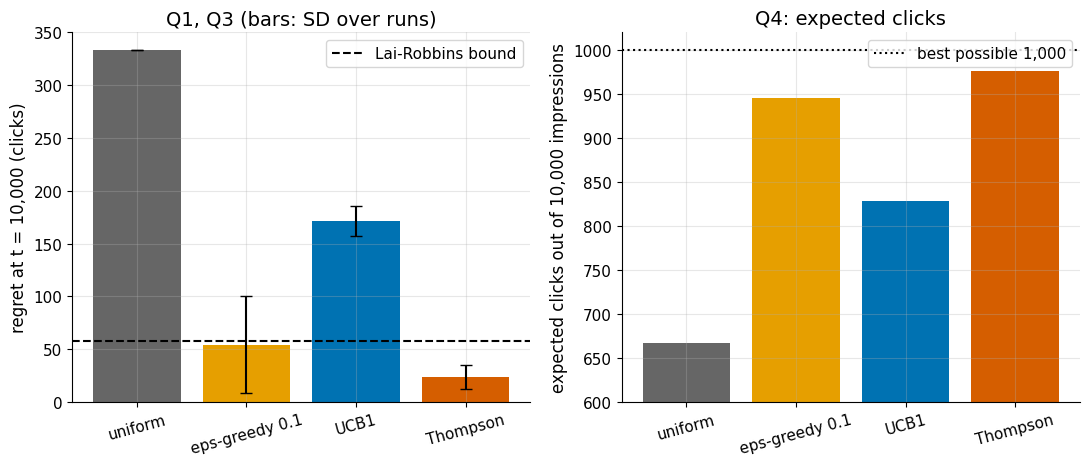

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); names = list(res); axes[0].bar(names, [res[n][0][-1] for n in names], yerr=[res[n][1].std() for n in names], color=[NEUTRAL, SIM, MAIN, HIGHLIGHT], capsize=4); axes[0].axhline(const * np.log(10000), color="black", linestyle="--", label="Lai-Robbins bound"); axes[0].set_ylabel("regret at t = 10,000 (clicks)"); axes[0].legend(); axes[0].set_title("Q1, Q3 (bars: SD over runs)"); axes[0].tick_params(axis="x", rotation=15)
axes[1].bar(names, [1000 - res[n][0][-1] for n in names], color=[NEUTRAL, SIM, MAIN, HIGHLIGHT]); axes[1].axhline(1000, color="black", linestyle=":", label="best possible 1,000"); axes[1].set_ylim(600, 1020); axes[1].set_ylabel("expected clicks out of 10,000 impressions"); axes[1].legend(); axes[1].set_title("Q4: expected clicks"); axes[1].tick_params(axis="x", rotation=15)
plt.show()

### 12.5 Interpretation and decision (Example 1)
- Average regret over 300 runs of 10,000 impressions: **uniform 333 clicks** (exactly the formula $\frac13\cdot10{,}000\cdot(0.06+0.04)$), $\varepsilon$-greedy **54** (SD over runs 46), UCB1 **171** (SD 14), **Thompson sampling 24** (SD 11). Thompson expects **976 clicks out of the best possible 1,000**, against 667 for the equal split: **310 more clicks** per 10,000 visitors.
- Thompson gives **95 %** of the impressions to the best banner (uniform 33 %, $\varepsilon$-greedy 88 %, UCB1 64 %). In the single run of 8.1 the banners were shown 126, 363 and 9,511 times, a regret of only 22 clicks.
- The Lai-Robbins constant is **6.28**, so the asymptotic bound at $T=10{,}000$ is 58 clicks. The regret divided by $\ln t$ rises as 0.58, 1.84, 2.56 at $t=100,\,1{,}000,\,10{,}000$ towards the bound; at this horizon Thompson sampling's regret (24) is still well below the asymptotic value, which is a limit as $T\to\infty$ and not a guarantee at each finite $T$. The regret computed from the average pull counts (23.57) equals the simulated curve.
- **Decision.** For picking among banners with traffic to spare, run a Thompson-sampling bandit instead of a fixed split: it loses about 7 % of the clicks that a fixed split would lose. Use a fixed A/B test only if you need a clean effect estimate for every arm.

---
### Example 2: two nearly identical creatives (a bandit is not a test)

**Scenario.** Banners with true click rates **6.0 %, 6.3 %** and a clearly worse **3.0 %**. We cannot hope to tell the first two apart in 10,000 impressions.

**Questions.** (1) How many impressions per arm would an A/B test need to separate 6.0 % from 6.3 % at 80 % power? (2) What are the regret and the allocation of Thompson sampling and of uniform allocation? (3) How often does Thompson sampling end up favouring the truly best arm?

Q1: A/B test needs 100,672 impressions per arm (total for 3 arms 302,016)
Q2: regret at 10,000: {'uniform': np.float64(120.0), 'Thompson': np.float64(21.3)} | allocation: {'uniform': array([0.333, 0.333, 0.333]), 'Thompson': array([0.39 , 0.581, 0.029])}


Q3: share of runs whose posterior mean favours the truly best arm: 0.707


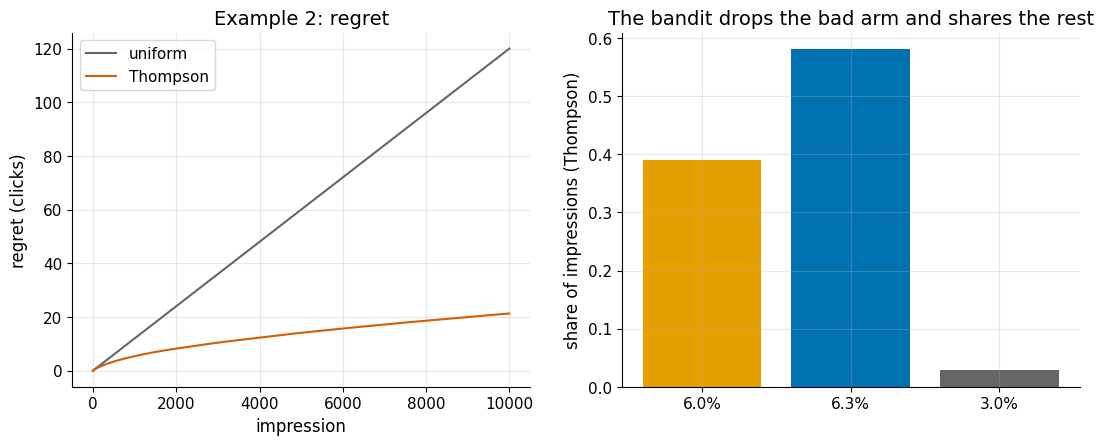

In [16]:
p2 = [0.060, 0.063, 0.030]; nab = 2 * (1.96 + 0.8416) ** 2 * 0.0615 * 0.9385 / 0.003 ** 2; r2 = {nm: play(pol, p2, 10000, 300, 20 + i) for i, (nm, pol) in enumerate([("uniform", "uniform"), ("Thompson", "ts")])}
print(f"Q1: A/B test needs {nab:,.0f} impressions per arm (total for 3 arms {3 * nab:,.0f})")
print("Q2: regret at 10,000:", {n: round(v[0][-1], 1) for n, v in r2.items()}, "| allocation:", {n: np.round(v[2], 3) for n, v in r2.items()})
g = np.random.default_rng(31); sB = np.zeros((300, 3)); fB = np.zeros((300, 3)); idx = np.arange(300)
for t in range(10000):
    a = np.argmax(g.beta(1 + sB, 1 + fB), axis=1); w = g.random(300) < np.array(p2)[a]; sB[idx, a] += w; fB[idx, a] += ~w
post_best = np.mean([np.argmax(g.beta(1 + sB[r], 1 + fB[r], size=(2000, 3)).mean(axis=0)) == 1 for r in range(300)]); print(f"Q3: share of runs whose posterior mean favours the truly best arm: {post_best:.3f}")
assert abs(nab - 100_700) < 3000 and r2["Thompson"][0][-1] < 0.3 * r2["uniform"][0][-1] and r2["Thompson"][0][-1] < 40
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6)); axes[0].plot(r2["uniform"][0], color=NEUTRAL, label="uniform"); axes[0].plot(r2["Thompson"][0], color=HIGHLIGHT, label="Thompson"); axes[0].set_xlabel("impression"); axes[0].set_ylabel("regret (clicks)"); axes[0].legend(); axes[0].set_title("Example 2: regret")
axes[1].bar(["6.0%", "6.3%", "3.0%"], r2["Thompson"][2], color=[SIM, MAIN, NEUTRAL]); axes[1].set_ylabel("share of impressions (Thompson)"); axes[1].set_title("The bandit drops the bad arm and shares the rest")
plt.show()

### 12.7 Interpretation and decision (Example 2)
- To tell 6.0 % from 6.3 % at 80 % power an A/B test needs **100,672 impressions per banner** (302,016 for three banners), 30 times the 10,000 impressions available. No test can separate the two here.
- Even so the bandit loses little: Thompson sampling has regret **21 clicks** against **120** for the equal split. It gives 3 % of the impressions to the bad banner (3.0 %) and splits the rest as **39 % / 58 %** between the near-equal banners. The posterior mean favours the truly best banner in only **71 %** of the runs: the bandit does **not** identify the winner reliably, but it does not need to; regret per impression is only $0.003$ clicks between the two close banners.
- **Decision.** A bandit minimises the cost of not knowing; it is the wrong tool if the goal is to state with confidence which of two similar variants is better. Decide first whether the aim is earning (regret) or learning (testing).

---
### Example 3: daily batches (delayed feedback)

**Scenario.** The ad server only refreshes its click statistics once per day (every 500 impressions). Compare Thompson sampling that updates after each impression with batch updates of 100, 500 and 2,000 impressions, using the banners of Example 1.

**Questions.** (1) Regret at 10,000 impressions for each update interval. (2) At which batch size does the benefit over uniform allocation start to vanish?

            regret  share on best  saving vs uniform
batch 1     25.346          0.946              0.924
batch 100   24.825          0.947              0.926
batch 500   29.480          0.938              0.912
batch 2000  69.944          0.859              0.790


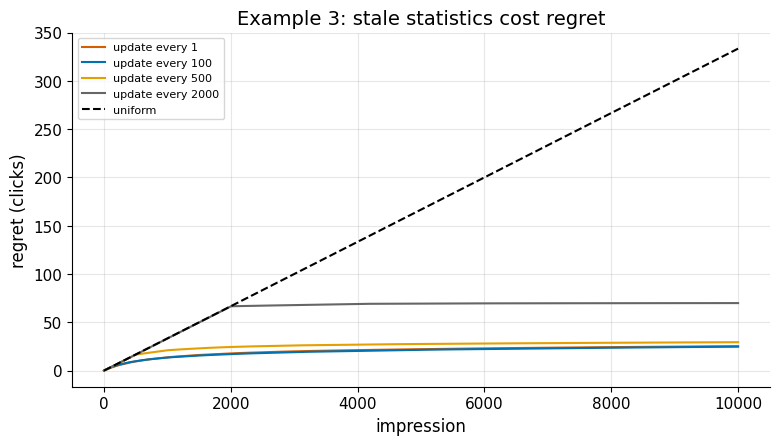

In [17]:
rb = {b: play("ts", ptrue, 10000, 300, 50, batch=b) for b in (1, 100, 500, 2000)}; ru = res["uniform"][0][-1]
tb = pd.DataFrame({f"batch {b}": {"regret": v[0][-1], "share on best": v[2][2], "saving vs uniform": 1 - v[0][-1] / ru} for b, v in rb.items()}).T; print(tb.round(3).to_string())
assert rb[1][0][-1] < rb[500][0][-1] < rb[2000][0][-1] and rb[500][0][-1] < 0.6 * ru and rb[2000][0][-1] < ru
fig, ax = plt.subplots(figsize=(9, 4.6))
for (b, v), colr in zip(rb.items(), [HIGHLIGHT, MAIN, SIM, NEUTRAL]): ax.plot(v[0], color=colr, label=f"update every {b}")
ax.plot(res["uniform"][0], color="black", linestyle="--", label="uniform"); ax.set_xlabel("impression"); ax.set_ylabel("regret (clicks)"); ax.legend(fontsize=8); ax.set_title("Example 3: stale statistics cost regret")
plt.show()

### 12.9 Interpretation and decision (Example 3)
- Regret for Thompson sampling with updates after every impression: **25.3**; every 100 impressions: **24.8**; every 500: **29.5**; every 2,000: **69.9**. The savings against the uniform split are **92 %, 93 %, 91 %** and **79 %**.
- Daily batches of 500 impressions (5 % of the horizon) cost only 4 extra clicks; a refresh interval of 2,000 impressions (20 % of the horizon) triples the regret but still saves most of the loss of a fixed split.
- **Decision.** Batch updates are fine as long as each batch is small relative to the horizon; refresh the statistics at least a few times per test period. Wait for delayed conversions when they matter, and keep exploring in the meantime.

## 13. Where it is used

### Statistics
- **Sequential design and adaptive clinical trials** (response-adaptive randomisation); **dose finding**; the exploration-exploitation trade-off is the core of sequential decision theory.

### Data science
- **Website and ad optimisation:** banners, headlines, email subject lines, recommendation slots; **dynamic pricing**; **notifications**; many experimentation platforms offer a "bandit" mode next to A/B tests.
- **When to prefer an A/B test:** when an unbiased estimate of the effect size is needed, when the effect is delayed, or when the metric cannot be observed quickly.

### ML and AI
- **Recommenders and ranking** with contextual bandits (linear Thompson sampling, LinUCB); **hyper-parameter search** and **LLM prompt/route selection** as bandits; **reinforcement learning** exploration (Thompson sampling over value functions, posterior sampling for RL).

## 14. Common pitfalls and misconceptions

- **Using a bandit when the effect needs a clean estimate:** adaptive sampling biases the naive estimates of rarely played arms (and inflates the best arm's); report the posterior and keep a small exploration share if an estimate matters.
- **Non-stationarity:** click rates change with time of day and season; a standard bandit assumes fixed rates (use discounting or sliding windows).
- **Delayed rewards** (purchases days after the click) need batch-aware updates (Example 3).
- **Forgetting the cost of a wrong prior:** an over-confident prior on a bad arm delays its exploration; use weak priors.
- **Fixed $\varepsilon$ forever** wastes a constant share of traffic: prefer a decreasing $\varepsilon$, UCB or Thompson sampling.
- **Judging by one run:** regret is random; compare averages over many runs and look at the spread.
- **Thinking the bandit "finds the winner":** it minimises regret, which is a different goal from identifying the winner with a stated error probability (Example 2).

## 15. Exercises

1. For two arms with rates 0.5 and 0.6 compute the Lai-Robbins constant and the bound at $T=1{,}000$.
2. A uniform split of 6,000 impressions over three banners with rates 3 %, 5 % and 8 %: compute the expected number of clicks lost.
3. Simulate Thompson sampling for the rates 0.05 and 0.10 for 2,000 impressions (300 runs) and report the average regret and the share on the better arm.
4. Implement $\varepsilon$-greedy with $\varepsilon_t=\min(1,\,5/t)$ and compare its regret with $\varepsilon=0.1$ in Example 1.
5. In Example 1, how does the regret of Thompson sampling change if the prior is Beta(20, 180) for every arm (a strong prior at 10 %)? Explain.
6. (Harder) Run Thompson sampling with a Gaussian model for revenue per visitor: arms with true means 10, 11 and 12 dollars, SD 8 dollars, 5,000 visitors; report regret and allocation.

Solutions are at the end.

## 16. Summary table

| Policy | Regret growth | Needs | Weakness |
|---|---|---|---|
| Uniform (A/B/n) | linear, $\bar\Delta T$ | nothing | wastes traffic on bad arms |
| $\varepsilon$-greedy | linear for fixed $\varepsilon$ | $\varepsilon$ | forever exploring |
| UCB1 | logarithmic | confidence bounds | conservative |
| Thompson | logarithmic, matches Lai-Robbins | a prior and posterior sampling | assumes stationarity |
| Bound | $\sum\Delta_k/\mathrm{KL}\cdot\ln T$ | | |
| tools | `rng.beta`, `argmax`, `np.cumsum` | | |

## Solutions

In [18]:
c1 = 0.1 / kl(0.5, 0.6); print(f"1: Lai-Robbins constant {c1:.2f}, bound at T = 1,000: {c1 * np.log(1000):.1f} clicks (KL = {kl(0.5, 0.6):.5f})")
print("2: expected clicks lost:", 2000 * ((0.08 - 0.03) + (0.08 - 0.05) + 0), "= 2,000 impressions per banner times the gaps")
r3 = play("ts", [0.05, 0.10], 2000, 300, 7); print(f"3: regret {r3[0][-1]:.1f} clicks, share on the better arm {r3[2][1]:.3f}")
def eps_decay(p, T, R, seed):
    g = np.random.default_rng(seed); K = len(p); p = np.asarray(p); s = np.zeros((R, K)); n = np.zeros((R, K)); idx = np.arange(R); reg = np.zeros(R)
    for t in range(1, T + 1):
        greedy = np.argmax(np.where(n == 0, 1.0, s / np.maximum(n, 1)) + 1e-9 * g.random((R, K)), axis=1); a = np.where(g.random(R) < min(1, 5 / t), g.integers(0, K, R), greedy); w = g.random(R) < p[a]; s[idx, a] += w; n[idx, a] += 1; reg += p.max() - p[a]
    return reg.mean()
print(f"4: epsilon_t = 5/t: regret {eps_decay(ptrue, 10000, 300, 8):.1f} vs fixed 0.1: {res['eps-greedy 0.1'][0][-1]:.1f} vs Thompson {res['Thompson'][0][-1]:.1f}")
def ts_prior(p, T, R, seed, a0, b0):
    g = np.random.default_rng(seed); K = len(p); p = np.asarray(p); s = np.zeros((R, K)); f = np.zeros((R, K)); idx = np.arange(R); reg = 0.0
    for t in range(T): a = np.argmax(g.beta(a0 + s, b0 + f), axis=1); w = g.random(R) < p[a]; s[idx, a] += w; f[idx, a] += ~w; reg += (p.max() - p[a]).mean()
    return reg
print(f"5: regret with the Beta(20, 180) prior: {ts_prior(ptrue, 10000, 300, 9, 20, 180):.1f} vs flat {res['Thompson'][0][-1]:.1f}")
g = np.random.default_rng(10); mu = np.array([10.0, 11.0, 12.0]); sg = 8.0; R6 = 200; n6 = np.zeros((R6, 3)); sm = np.zeros((R6, 3)); idx = np.arange(R6); reg6 = 0.0; pulls6 = np.zeros(3)
for t in range(5000):
    post_sd = sg / np.sqrt(np.maximum(n6, 0) + 1); post_mean = sm / (n6 + 1); a = np.argmax(g.normal(post_mean, post_sd), axis=1); y = g.normal(mu[a], sg); n6[idx, a] += 1; sm[idx, a] += y; reg6 += (mu.max() - mu[a]).mean(); pulls6 += np.bincount(a, minlength=3) / R6
print(f"6: Gaussian Thompson sampling: regret {reg6:.1f} dollars (uniform would be {5000 * (mu.max() - mu.mean()):.0f}), allocation {np.round(pulls6 / 5000, 3)}")
assert r3[0][-1] < 40 and abs(c1 * np.log(1000) - 0.1 / kl(0.5, 0.6) * np.log(1000)) < 1e-9

1: Lai-Robbins constant 4.90, bound at T = 1,000: 33.8 clicks (KL = 0.02041)
2: expected clicks lost: 160.0 = 2,000 impressions per banner times the gaps
3: regret 8.4 clicks, share on the better arm 0.916


4: epsilon_t = 5/t: regret 121.0 vs fixed 0.1: 54.4 vs Thompson 23.6


5: regret with the Beta(20, 180) prior: 35.0 vs flat 23.6


6: Gaussian Thompson sampling: regret 591.4 dollars (uniform would be 5000), allocation [0.023 0.073 0.904]


**1.** $\mathrm{KL}(0.5\|0.6)=0.0204$, constant $=0.1/0.0204=$ **4.90**, bound at $T=1{,}000$: $4.90\ln1000=$ **33.8 clicks**.

**2.** Each banner gets 2,000 impressions: clicks lost $=2{,}000\times(0.05+0.03)=$ **160** against always showing the 8 % banner.

**3.** Thompson sampling with rates 0.05 and 0.10 over 2,000 impressions: regret **8.4 clicks**, share on the better arm **0.92**.

**4.** With $\varepsilon_t=\min(1,5/t)$ the regret is **121** clicks, worse than the fixed $\varepsilon=0.1$ (54) and Thompson sampling (24): decaying exploration too fast lets early bad luck lock in a wrong arm in some runs.

**5.** A strong Beta(20, 180) prior (10 % for every arm, worth 200 impressions) raises the regret to **35** against 24 with the flat prior: the prior slows the discovery that the best banner is at 10 % and the others lower, and it is a mildly wrong assumption for arm A (4 %).

**6.** Gaussian Thompson sampling for revenue (means 10, 11, 12; SD 8; 5,000 visitors): regret **591 dollars** against **5,000** for the equal split; the allocation is 2 %, 7 % and **90 %** on the best arm.